# 05 · Aporte de cada pieza, techos medidos y recursos

**Pregunta:** ¿cada componente de la política aporta algo, queda margen real de mejora y cuánto cuesta en CPU y memoria?
Se mide la ablación sobre la propuesta final, las reglas de mejoras que se probaron y no se adoptaron, los techos de agrupación, de p95 y de la espera para agrupar,
y la CPU y la RAM al estilo del evaluador. Cada tabla sale de un CSV de `outputs/csvs/`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # solucion/
REPO = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import plotstyle as PS, figs
PS.apply()
CSV, FIG = ROOT / "outputs" / "csvs", ROOT / "outputs" / "figs"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def show(fig):
    display(fig); plt.close(fig)

## 1 · Ablación sobre la propuesta final (afinado y decisión, 28 escenarios)
ΔJ a secas sugiere que el riesgo de fallo, el coste sombra y el emparejamiento no aportan; los puntos de cohorte y la dominancia sobre el starter dicen otra cosa,
porque J suma magnitudes relativas y no mira si se gana al starter escenario a escenario.

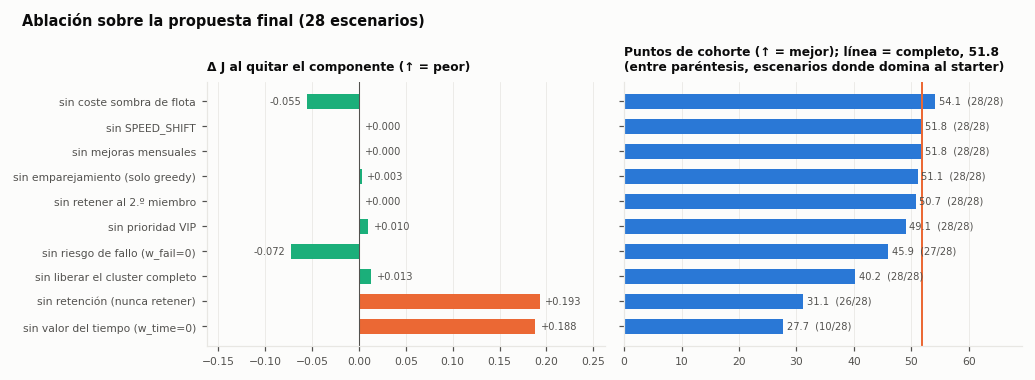

,variante,J,coste_vs_ref,lead_vs_ref,p95_vs_ref,rcp,lote_medio,gates_malos,cpu_neta_5k_s,domina_starter_de_28,puntos_proxy
0,completo,3.658,1.087,0.804,0.947,9.909,1.291,0,0.875,28,51.796
1,sin retención (nunca retener),3.850,1.252,0.831,0.951,9.910,1.030,0,1.062,26,31.143
2,sin retener al 2.º miembro,3.658,1.087,0.804,0.946,9.909,1.290,0,NaN,28,50.709
3,sin liberar el cluster completo,3.670,1.087,0.815,0.949,9.909,1.291,0,NaN,28,40.245
4,sin valor del tiempo (w_time=0),3.846,0.840,0.995,0.989,9.889,1.288,0,NaN,10,27.724
5,sin riesgo de fallo (w_fail=0),3.585,1.012,0.843,0.954,9.913,1.290,0,NaN,27,45.939
6,sin prioridad VIP,3.668,1.071,0.807,0.947,9.907,1.291,0,NaN,28,49.056
7,sin coste sombra de flota,3.602,1.058,0.811,0.947,9.912,1.291,0,NaN,28,54.148
8,sin emparejamiento (solo greedy),3.661,1.086,0.807,0.948,9.909,1.291,0,0.812,28,51.117
9,sin mejoras mensuales,3.658,1.087,0.804,0.947,9.909,1.291,0,0.750,28,51.796


In [2]:
abf = pd.read_csv(CSV/"ablation_final.csv")
import matplotlib.pyplot as plt
a = abf[abf.variante != "completo"].copy(); full = abf[abf.variante=="completo"].iloc[0]; a["dJ"] = a.J - full.J; a = a.sort_values("puntos_proxy")
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.4), sharey=True)
b = ax[0].barh(a.variante, a.dJ, color=[PS.ORANGE if v > 0.02 else PS.AQUA for v in a.dJ], height=0.62)
for r, v in zip(b, a.dJ): ax[0].text(v + (0.006 if v >= 0 else -0.006), r.get_y()+r.get_height()/2, f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=6.5, color=PS.INK2)
ax[0].axvline(0, color=PS.INK2, lw=0.7); ax[0].grid(axis="y", visible=False); ax[0].set_xlim(a.dJ.min() - 0.09, a.dJ.max() + 0.07)
ax[0].set_title("Δ J al quitar el componente (↑ = peor)", fontsize=8)
b2 = ax[1].barh(a.variante, a.puntos_proxy, color=PS.BLUE, height=0.62)
for r, v, d in zip(b2, a.puntos_proxy, a.domina_starter_de_28): ax[1].text(v + 0.6, r.get_y()+r.get_height()/2, f"{v:.1f}  ({int(d)}/28)", va="center", fontsize=6.5, color=PS.INK2)
ax[1].axvline(full.puntos_proxy, color=PS.ORANGE, lw=1.3); ax[1].grid(axis="y", visible=False); ax[1].set_xlim(0, a.puntos_proxy.max() * 1.28)
ax[1].set_title(f"Puntos de cohorte (↑ = mejor); línea = completo, {full.puntos_proxy:.1f}\n(entre paréntesis, escenarios donde domina al starter)", fontsize=8)
fig.suptitle("Ablación sobre la propuesta final (28 escenarios)", fontsize=9.5, fontweight="bold", x=0.02, ha="left"); fig.tight_layout(); fig.savefig(FIG/"ablacion_final.png"); show(fig)
abf.round(3)

## 2 · Reglas SPEED_SHIFT y EXPANDED_CAPACITY (probadas, no adoptadas)
`SPEED_SHIFT` se compra si el valor del tiempo ahorrado el periodo anterior (20 % del trayecto de ida × `w_time`) cubre κ veces su coste; `EXPANDED_CAPACITY` si hubo muchos grupos partidos por capacidad.

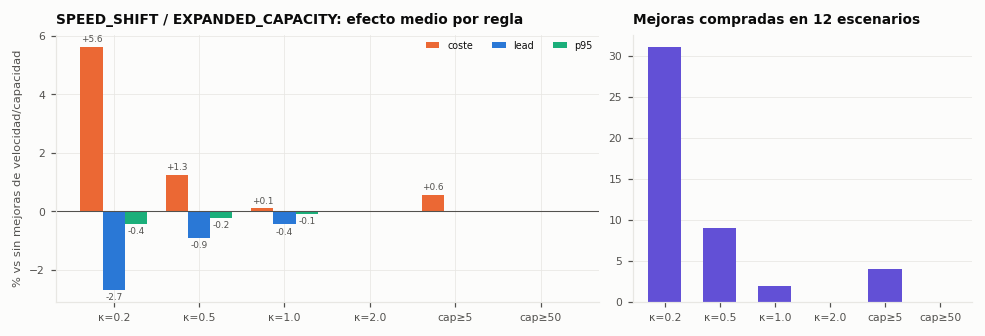

,variante,speed_total,cap_total,extra_total
0,base,0,0,6
1,speed_k0.2,31,0,4
2,speed_k0.5,9,0,6
3,speed_k1.0,2,0,6
4,speed_k2.0,0,0,6
5,cap_s5,0,4,6
6,cap_s50,0,0,6


In [3]:
sp = pd.read_csv(CSV/"speed_capacity_rules.csv")
scen_sp = [c[5:] for c in sp.columns if c.startswith("cost_")]
show(figs.speed_rules(sp, scen_sp))
sp[["variante","speed_total","cap_total","extra_total"]]

## 3 · Techos medidos
- **Lotes:** cada cluster necesita al menos un lote en el primer intento y cada reintento fallido, como mucho, uno más; la cota superior es clusters más fallos.
- **p95:** parte es irreducible, porque la mayoría de los fallos son ausencias del cliente (no dependen del transportista) y el reintento espera 1 440 min. La referencia «siempre el transportista más rápido» marca la cota práctica.
- **Espera para agrupar:** un oráculo que conoce el tamaño real de cada cluster acota cuánto podría mejorar cualquier regla de espera más inteligente.

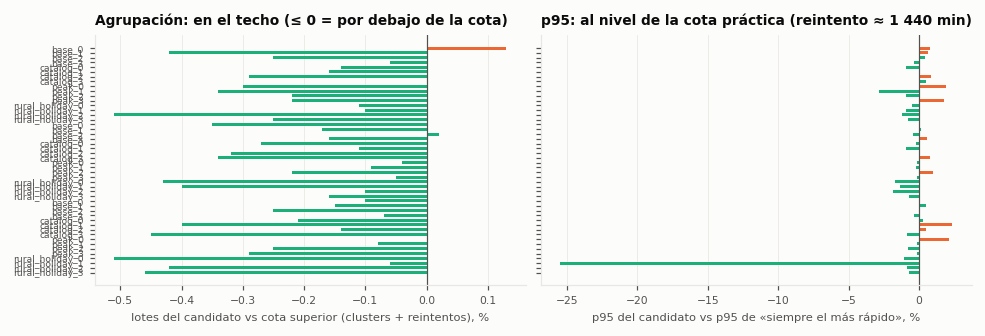

,lote_vs_cota_sup_pct,p95_vs_eta_pct
mean,-0.21,-0.66
min,-0.51,-25.47
max,0.13,2.37


In [4]:
ce = pd.read_csv(CSV/"ceiling_batches_p95.csv"); show(figs.ceilings(ce)); ce[["lote_vs_cota_sup_pct","p95_vs_eta_pct"]].describe().loc[["mean","min","max"]].round(2)

In [5]:
orc = pd.read_csv(CSV/"techo_retencion_oraculo.csv"); print("Oráculo frente al archivo final (negativo = mejora del oráculo):"); display(orc)
post = pd.read_csv(CSV/"espera_posterior_barrido.csv"); print("Regla de espera por posterior frente a la regla final (afinado y decisión):"); post

Oráculo frente al archivo final (negativo = mejora del oráculo):


,scenario,coste_pct,lead_pct,p95_pct,rcp_delta,lote_oraculo,lote_final
0,tune_base_0,-0.70,-3.70,-0.78,0.003,1.279,1.274
1,tune_peak_1,-0.21,-2.51,-0.26,0.006,1.407,1.406
2,tune_rural_holiday_0,-0.42,-0.14,0.00,0.001,1.291,1.288
3,tune_catalog_1,-0.25,-2.81,-0.45,0.007,1.146,1.143
4,hold_base_1,-0.27,-2.04,-0.78,0.001,1.316,1.314
5,hold_peak_2,0.15,-1.63,-0.45,-0.006,1.360,1.358


Regla de espera por posterior frente a la regla final (afinado y decisión):


,cand,coste%,lead%,p95%,rcp,lote,gates,n,gana lead,gana coste
0,regla_anterior,0.00,0.00,0.00,0.0000,1.291,28,28,0,0
1,posterior_F150,15.20,3.38,0.49,0.0012,1.030,28,28,1,0
2,posterior_F300,6.83,0.15,-0.02,-0.0003,1.162,28,28,15,0
3,posterior_F500,3.58,-0.25,-0.07,0.0024,1.217,28,28,18,0
4,posterior_F800,2.09,-0.23,-0.11,0.0040,1.249,28,28,18,0
5,posterior_F1300,1.08,-0.20,0.01,0.0020,1.271,28,28,22,0
6,posterior_F2500,0.31,-0.22,-0.10,0.0001,1.286,28,28,20,2


## 4 · CPU y RAM al estilo del evaluador
Un calentamiento y la **mediana de 3** ejecuciones, en serie e intercaladas (estrategia nula, starter y final), sobre dos escenarios de carga (5 000 y 150 000 tarjetas).
CPU neta = CPU menos la CPU de la estrategia nula, que es el piso del motor.

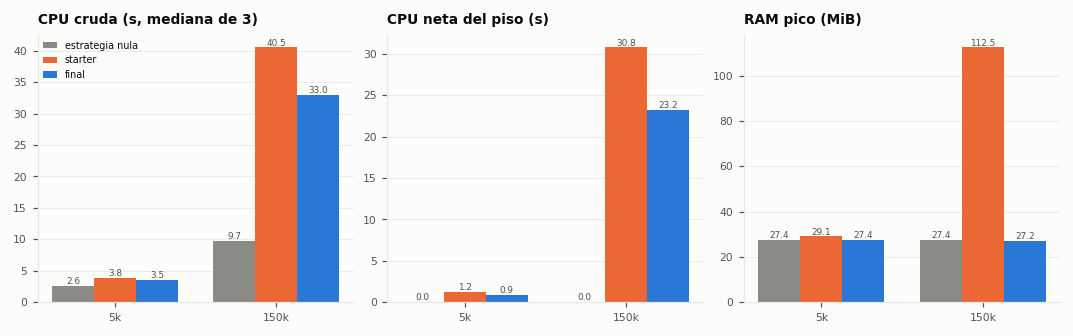

,escenario,estrategia,status,admitted,delivered,returned,unresolved,hold_breaches,sla_breach_rate,rcp,cost_total,lead_mean,lead_p95,avg_batch,pristine,cpu_s_mediana3,cpu_s_runs,cpu_neta_s,rss_mib_mediana3,rss_neta_mib,wall_s_mediana3
0,public_5k,noop,COMPLETED,5000,0,0,5000,5000,1.00,1.00,10000000,NaN,NaN,0.00,True,2.62,"[2.62, 2.44, 2.62]",0.00,27.39,0.00,7.33
1,public_5k,starter,COMPLETED,5000,4983,1,16,42,0.01,9.87,4443213,230.56,1576.0,1.00,True,3.84,"[3.84, 3.72, 4.09]",1.22,29.07,1.68,11.44
2,public_5k,final,COMPLETED,5000,5000,0,0,0,0.00,9.96,3593368,194.60,1523.0,1.27,True,3.48,"[3.22, 3.5, 3.48]",0.86,27.36,-0.02,10.17
0,public_150k,noop,COMPLETED,150000,0,0,150000,150000,1.00,1.00,300000000,NaN,NaN,0.00,True,9.73,"[9.8, 9.02, 9.73]",0.00,27.39,0.00,48.52
1,public_150k,starter,COMPLETED,150000,149800,32,168,837,0.01,9.88,138126792,225.59,1565.0,1.00,True,40.52,"[42.5, 40.52, 38.72]",30.78,112.50,85.12,147.21
2,public_150k,final,COMPLETED,150000,149982,18,0,0,0.00,9.93,111100128,193.48,1515.0,1.28,True,32.95,"[32.7, 34.34, 32.95]",23.22,27.20,-0.19,131.09


In [6]:
cp = {s: pd.read_csv(CSV/f"cpu_eval_{s}.csv") for s in ["public_5k","public_150k"]}
show(figs.cpu_bars(cp))
pd.concat(cp.values()).round(2)